# Dataset Validation

Notebook configurabile per verificare la distribuzione delle classi nei dataset di segmentazione chirurgica.

Il notebook calcola **sull'intero dataset**, senza sampling:
- numero di esempi per split;
- numero di esempi in cui compare ogni classe;
- percentuale di esempi in cui compare ogni classe;
- numero totale di pixel per classe;
- percentuale dei pixel per classe.

La logica di split viene mantenuta: se il dataset possiede split ufficiali/metadati vengono usati quelli; altrimenti viene usata la configurazione Hydra.

# CONFIGURAZIONE PRINCIPALE

In [1]:
# Change ONLY this
#   "baseline/cholec_seg8k"
#   "baseline/dsad"
#   "baseline/sarrarp50"
#   etc

DATASET_CONFIG = "baseline/cholec_seg8k"

# Nome del config principale Hydra del progetto.
HYDRA_CONFIG_NAME = "config"

PROJECT_ROOT = None

# Se True, stampa informazioni utili per il debug.
DEBUG = True


In [2]:
# ============================================================
# SETUP PROGETTO
# ============================================================

from pathlib import Path
import sys


def find_project_root(start=None):
    """Find the repository root containing configs/ and src/."""
    start = Path(start or Path.cwd()).resolve()

    candidates = [start, *start.parents]

    for path in candidates:
        if (path / "src").is_dir() and (path / "configs").is_dir():
            return path

    raise FileNotFoundError(
        "Impossibile trovare la root della repo. "
        "Imposta PROJECT_ROOT manualmente nella cella precedente."
    )


if PROJECT_ROOT is None:
    PROJECT_ROOT = find_project_root()
else:
    PROJECT_ROOT = Path(PROJECT_ROOT).resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset config: {DATASET_CONFIG}")
print(f"Hydra config: {HYDRA_CONFIG_NAME}")


Project root: /homes/cmininno/tesi/surgical_scene_segmentation
Dataset config: baseline/cholec_seg8k
Hydra config: config


In [3]:
# ============================================================
# IMPORT
# ============================================================

import numpy as np
import pandas as pd
from omegaconf import OmegaConf
                
from hydra import compose, initialize_config_dir
from hydra.utils import instantiate


In [4]:
# ============================================================
# CARICAMENTO CONFIG + DATASET
# ============================================================

config_dir = PROJECT_ROOT / "configs"

with initialize_config_dir(
    version_base=None,
    config_dir=str(config_dir),
):
    cfg = compose(
        config_name=HYDRA_CONFIG_NAME,
        overrides=[f"dataset={DATASET_CONFIG}"],
    )

print("Configurazione caricata:")
print(OmegaConf.to_yaml(cfg))


dataset = instantiate(cfg.data.dataset)

print(f"Dataset: {type(dataset).__name__}")
print(f"Samples: {len(dataset.samples)}")
print(f"Classes: {dataset.class_names}")


Configurazione caricata:
name: cholecseg8k
data:
  name: cholecseg8k
  dataset:
    _target_: src.datasets.cholecseg8k.CholecSeg8kDataset
    root: ${paths.data}/CholecSeg8k
  num_classes: 13
  split:
    strategy: percentage
    group_by: video
    seed: 42
    stratified: true
    train_ratio: 0.7
    val_ratio: 0.3
    test_ratio: 0.0
preprocessing:
  image:
    size:
    - 240
    - 427
    channel_first: true
    dtype: float32
    normalize: true
  mask:
    channel_first: true
    dtype: long
  padding:
    enabled: true
    divisor: 16
augmentation:
  train:
    enabled: true
    horizontal_flip:
      enabled: true
      probability: 0.5
    scaling:
      enabled: true
      range:
      - -0.1
      - 0.1
      probability: 1.0
    gaussian_blur:
      enabled: true
      probability: 1.0
      kernel_sizes:
      - 3
      - 5
      - 7
      sigmas:
      - 0.8
      - 1.1
      - 1.4
    random_crop:
      enabled: true
      size:
      - 256
      - 256
  validation:
  

In [5]:
# ============================================================
# FUNZIONI DI SUPPORTO
# ============================================================

def get_samples(dataset):
    samples = getattr(dataset, "samples", None)
    if samples is None:
        raise AttributeError(
            f"{type(dataset).__name__} non espone 'samples'."
        )
    return list(samples)


def get_class_names(dataset):
    names = getattr(dataset, "class_names", None)
    if names is None:
        names = getattr(dataset, "CLASS_NAMES", None)
    if names is None:
        raise AttributeError(
            f"{type(dataset).__name__} non espone class_names/CLASS_NAMES."
        )
    return list(names)


def to_numpy(value):
    if hasattr(value, "detach"):
        value = value.detach().cpu().numpy()
    return np.asarray(value)


def load_raw_sample(dataset, index):
    # Evita eventuali augmentation/runtime transform.
    loader = getattr(dataset, "_load_sample", None)
    if callable(loader):
        return loader(index)
    return dataset[index]


## Risoluzione degli split

La regola è semplice:

1. se `dataset.samples` contiene `split`, vengono usati gli split già definiti dal dataset;
2. altrimenti vengono usati gli split generati dalla configurazione Hydra.

Non viene applicato alcun limite al numero di campioni.

In [6]:
# ============================================================
# RISOLUZIONE SPLIT
# ============================================================

def metadata_splits(dataset):
    splits = {}
    for index, sample in enumerate(get_samples(dataset)):
        split = sample.get("split")
        if split is not None:
            splits.setdefault(str(split), []).append(index)
    return splits


def resolve_splits(dataset, cfg):
    existing = metadata_splits(dataset)

    if existing:
        return existing

    split_cfg = cfg.data.get("split")

    if split_cfg is None:
        raise ValueError(
            "Il dataset non contiene split nei sample e cfg.dataset.split non esiste."
        )

    strategy = split_cfg.get("strategy")
                
    if strategy != "percentage":
        raise ValueError(
            f"Strategia split non supportata dal notebook: {strategy}"
        )

    # Usiamo la funzione di split già presente nel progetto se disponibile.
    # Questo è importante per mantenere ESATTAMENTE la stessa logica usata dal training.
    try:
        from src.datasets.validation import generate_percentage_splits
    except ImportError as exc:
        raise ImportError(
            "Non trovo src.validation.dataset_validator. "
            "Salva il validator semplificato in questo percorso, oppure "
            "modifica l'import nella cella."
        ) from exc

    return generate_percentage_splits(
        dataset=dataset,
        split_config=split_cfg,
    )


splits = resolve_splits(dataset, cfg)

split_summary = pd.DataFrame([
    {
        "split": split_name,
        "samples": len(indices),
    }
    for split_name, indices in splits.items()
])

display(split_summary)


,split,samples
0,train,5360
1,validation,2720
2,test,0


## Distribuzione delle classi

Questa è la parte principale del validator. **Vengono analizzati tutti gli esempi di ogni split.**

`samples` = numero di immagini/mask in cui compare la classe.

`sample_percentage` = percentuale delle immagini dello split in cui compare la classe.

`pixels` = numero totale di pixel appartenenti alla classe.

`pixel_percentage` = percentuale dei pixel totali dello split appartenenti alla classe.

In [7]:
# ============================================================
# STATISTICHE COMPLETE
# ============================================================

def class_statistics(dataset, indices, split_name):
    class_names = get_class_names(dataset)
    class_count = len(class_names)

    pixel_counts = np.zeros(class_count, dtype=np.int64)
    sample_presence = np.zeros(class_count, dtype=np.int64)

    indices = list(indices)
    total_samples = len(indices)
    total_pixels = 0

    for index in indices:
        sample = load_raw_sample(dataset, int(index))
        mask = to_numpy(sample["mask"])

        if mask.ndim != 2:
            raise ValueError(
                f"Mask non 2D all'indice {index}: {mask.shape}"
            )

        total_pixels += mask.size

        labels, counts = np.unique(
            mask,
            return_counts=True,
        )

        for label, count in zip(labels, counts):
            label = int(label)

            if 0 <= label < class_count:
                pixel_counts[label] += int(count)
                sample_presence[label] += 1

    rows = []

    for class_id, class_name in enumerate(class_names):
        rows.append({
            "split": split_name,
            "class_id": class_id,
            "class": class_name,
            "samples": int(sample_presence[class_id]),
            "sample_percentage": (
                100.0 * sample_presence[class_id] / total_samples
                if total_samples else 0.0
            ),
            "pixels": int(pixel_counts[class_id]),
            "pixel_percentage": (
                100.0 * pixel_counts[class_id] / total_pixels
                if total_pixels else 0.0
            ),
        })

    return pd.DataFrame(rows)


statistics = pd.concat(
    [
        class_statistics(
            dataset,
            indices,
            split_name,
        )
        for split_name, indices in splits.items()
    ],
    ignore_index=True,
)

display(statistics)


,split,class_id,class,samples,sample_percentage,pixels,pixel_percentage
0,train,0,Background,5360,100.000000,535797674,24.385795
1,train,1,Abdominal Wall,4624,86.268657,410013131,18.660955
2,train,2,Liver,5360,100.000000,534385476,24.321522
3,train,3,Gastrointestinal Tract,2746,51.231343,46409566,2.112242
4,train,4,Fat,5039,94.011194,304187615,13.844511
5,train,5,Grasper,4158,77.574627,60016433,2.731532
6,train,6,Connective Tissue,1600,29.850746,75080239,3.417132
7,train,7,Blood,692,12.910448,13991063,0.636776
8,train,8,Cystic Duct,246,4.589552,1155394,0.052586
9,train,9,L-hook Electrocautery,2089,38.973881,37084296,1.687820


In [8]:
# ============================================================
# TABELLA COMPATTA PER IL REPORT / TESI
# ============================================================

report_table = statistics[
    [
        "split",
        "class",
        "samples",
        "sample_percentage",
        "pixels",
        "pixel_percentage",
    ]
].copy()

report_table["sample_percentage"] = report_table[
    "sample_percentage"
].round(2)

report_table["pixel_percentage"] = report_table[
    "pixel_percentage"
].round(2)

display(report_table)


,split,class,samples,sample_percentage,pixels,pixel_percentage
0,train,Background,5360,100.00,535797674,24.39
1,train,Abdominal Wall,4624,86.27,410013131,18.66
2,train,Liver,5360,100.00,534385476,24.32
3,train,Gastrointestinal Tract,2746,51.23,46409566,2.11
4,train,Fat,5039,94.01,304187615,13.84
5,train,Grasper,4158,77.57,60016433,2.73
6,train,Connective Tissue,1600,29.85,75080239,3.42
7,train,Blood,692,12.91,13991063,0.64
8,train,Cystic Duct,246,4.59,1155394,0.05
9,train,L-hook Electrocautery,2089,38.97,37084296,1.69


## Controllo rapido

La somma delle `pixel_percentage` di ogni split dovrebbe essere circa **100%** (a meno di label non valide che vengono ignorate).

In [9]:
# ============================================================
# SANITY CHECK PIXEL DISTRIBUTION
# ============================================================

pixel_check = (
    statistics
    .groupby("split", as_index=False)["pixel_percentage"]
    .sum()
    .rename(columns={"pixel_percentage": "pixel_percentage_sum"})
)

pixel_check["pixel_percentage_sum"] = pixel_check[
    "pixel_percentage_sum"
].round(4)

display(pixel_check)


,split,pixel_percentage_sum
0,test,0.0
1,train,100.0
2,validation,100.0


In [10]:
# ============================================================
# PIXEL DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt


for split_name in statistics["split"].unique():

    split_stats = statistics[
        statistics["split"] == split_name
    ].copy()

    plt.figure(figsize=(12, 6))

    plt.bar(
        split_stats["class"],
        split_stats["pixel_percentage"],
    )

    plt.xlabel("Class")
    plt.ylabel("Pixel percentage (%)")
    plt.title(
        f"Pixel distribution - {split_name}"
    )

    plt.xticks(
        rotation=45,
        ha="right",
    )

    plt.tight_layout()
    plt.show()

<Figure size 1200x600 with 1 Axes>

<Figure size 1200x600 with 1 Axes>

<Figure size 1200x600 with 1 Axes>

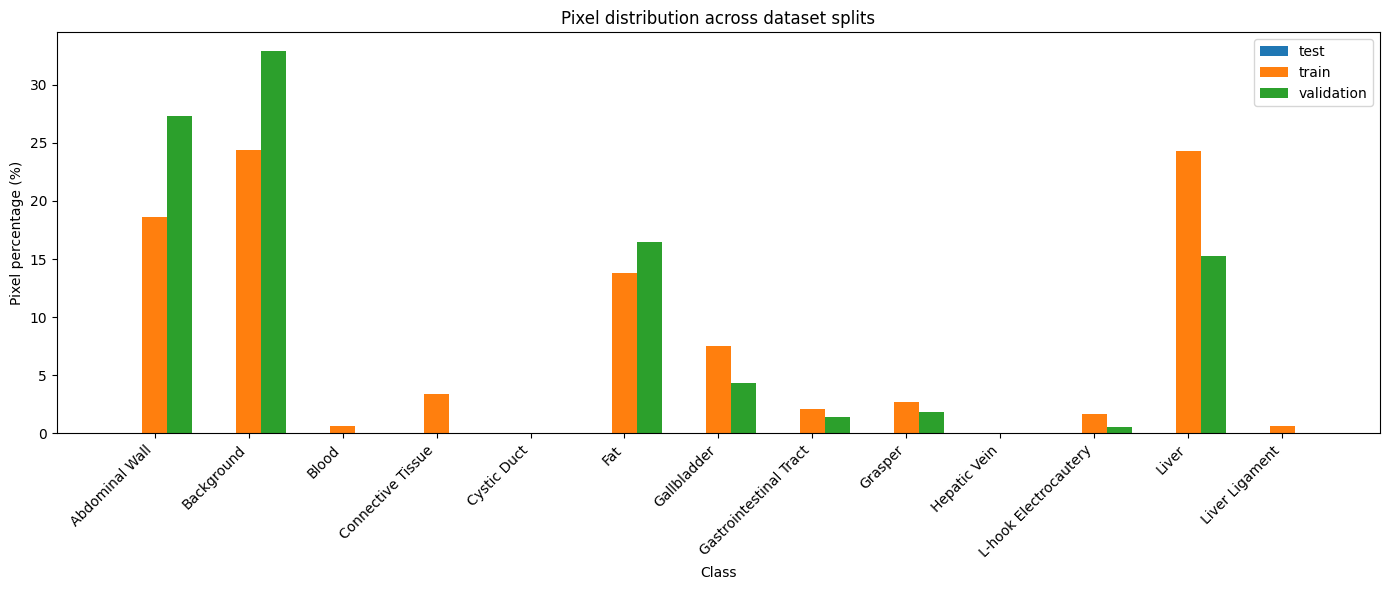

In [11]:
# ============================================================
# PIXEL DISTRIBUTION - TRAIN VS VALIDATION VS TEST
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


pivot = statistics.pivot(
    index="class",
    columns="split",
    values="pixel_percentage",
).fillna(0)

x = np.arange(len(pivot.index))
splits_to_plot = list(pivot.columns)

width = 0.8 / len(splits_to_plot)

plt.figure(figsize=(14, 6))

for i, split_name in enumerate(splits_to_plot):

    values = pivot[split_name].values

    plt.bar(
        x + i * width,
        values,
        width,
        label=split_name,
    )

plt.xlabel("Class")
plt.ylabel("Pixel percentage (%)")
plt.title("Pixel distribution across dataset splits")

plt.xticks(
    x + width * (len(splits_to_plot) - 1) / 2,
    pivot.index,
    rotation=45,
    ha="right",
)

plt.legend()
plt.tight_layout()
plt.show()

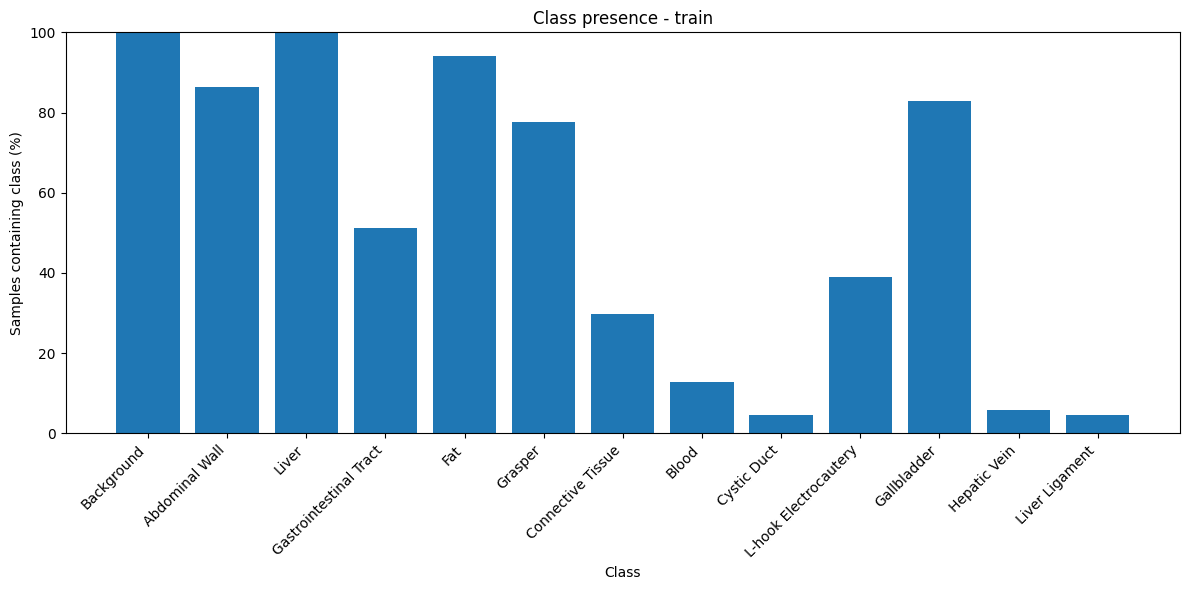

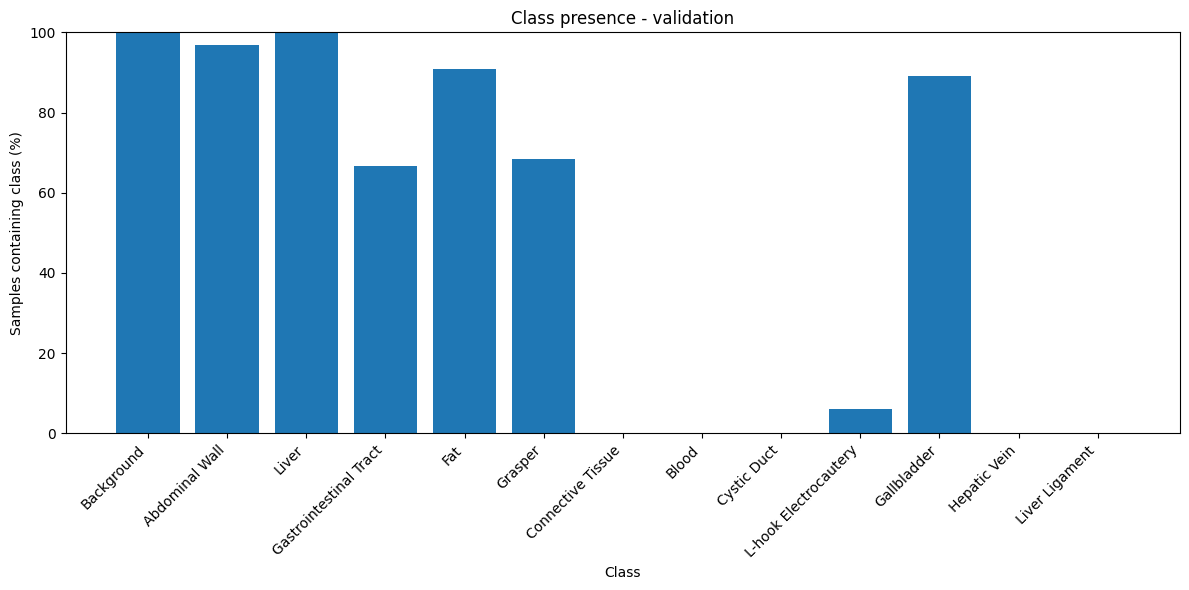

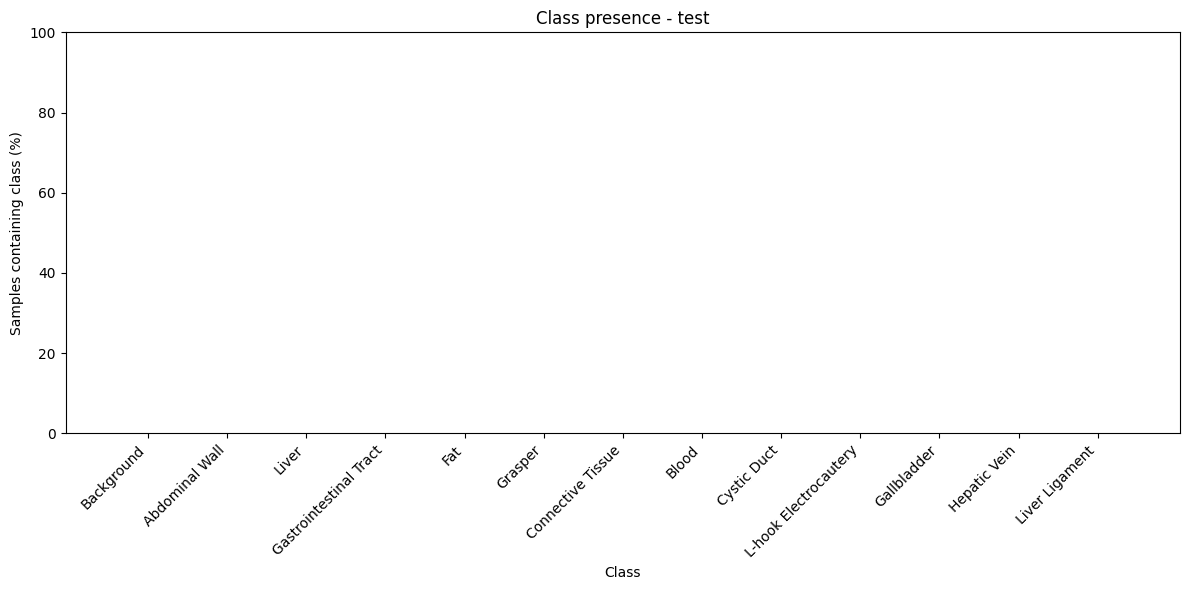

In [12]:
# ============================================================
# CLASS PRESENCE IN SAMPLES
# ============================================================

import matplotlib.pyplot as plt


for split_name in statistics["split"].unique():

    split_stats = statistics[
        statistics["split"] == split_name
    ].copy()

    plt.figure(figsize=(12, 6))

    plt.bar(
        split_stats["class"],
        split_stats["sample_percentage"],
    )

    plt.xlabel("Class")
    plt.ylabel("Samples containing class (%)")
    plt.title(
        f"Class presence - {split_name}"
    )

    plt.xticks(
        rotation=45,
        ha="right",
    )

    plt.ylim(0, 100)

    plt.tight_layout()
    plt.show()

In [13]:
# ============================================================
# QUALITATIVE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


def prepare_image(image):
    """
    Convert image to HWC format suitable for matplotlib.
    """

    image = np.asarray(image)

    if image.ndim == 2:
        return image

    if image.ndim == 3:

        # CHW -> HWC
        if image.shape[0] in (1, 3, 4):
            image = np.transpose(
                image,
                (1, 2, 0),
            )

        # Remove single channel dimension
        if image.shape[-1] == 1:
            image = image[..., 0]

    return image


def normalize_image(image):
    """
    Normalize image for visualization.
    """

    image = image.astype(np.float32)

    min_value = image.min()
    max_value = image.max()

    if max_value > min_value:
        image = (
            image - min_value
        ) / (
            max_value - min_value
        )

    return image


def visualize_sample(
    dataset,
    index,
    class_names,
    alpha=0.5,
):
    """
    Display:
        1. Original image
        2. Ground truth
        3. Overlay
    """

    sample = load_raw_sample(
        dataset,
        index,
    )

    image = prepare_image(
        to_numpy(sample["image"])
    )

    mask = to_numpy(
        sample["mask"]
    )

    image = normalize_image(image)

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6),
    )

    # --------------------------------------------------------
    # Original image
    # --------------------------------------------------------

    axes[0].imshow(image)

    axes[0].set_title(
        f"Image - index {index}"
    )

    axes[0].axis("off")

    # --------------------------------------------------------
    # Ground truth
    # --------------------------------------------------------

    axes[1].imshow(
        mask,
        interpolation="nearest",
    )

    axes[1].set_title(
        "Ground Truth"
    )

    axes[1].axis("off")

    # --------------------------------------------------------
    # Overlay
    # --------------------------------------------------------

    axes[2].imshow(image)

    axes[2].imshow(
        mask,
        alpha=alpha,
        interpolation="nearest",
    )

    axes[2].set_title(
        "Ground Truth Overlay"
    )

    axes[2].axis("off")

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    present_classes = np.unique(mask)

    legend_text = []

    for class_id in present_classes:

        class_id = int(class_id)

        if 0 <= class_id < len(class_names):
            legend_text.append(
                f"{class_id}: {class_names[class_id]}"
            )

    fig.text(
        0.5,
        0.01,
        " | ".join(legend_text),
        ha="center",
        fontsize=10,
    )

    plt.tight_layout()
    plt.show()

In [14]:
# ============================================================
# RANDOM SAMPLES
# ============================================================

import random


def visualize_random_samples(
    dataset,
    indices,
    class_names,
    n_samples=5,
):

    indices = list(indices)

    n_samples = min(
        n_samples,
        len(indices),
    )

    selected_indices = random.sample(
        indices,
        n_samples,
    )

    for index in selected_indices:

        visualize_sample(
            dataset=dataset,
            index=index,
            class_names=class_names,
        )

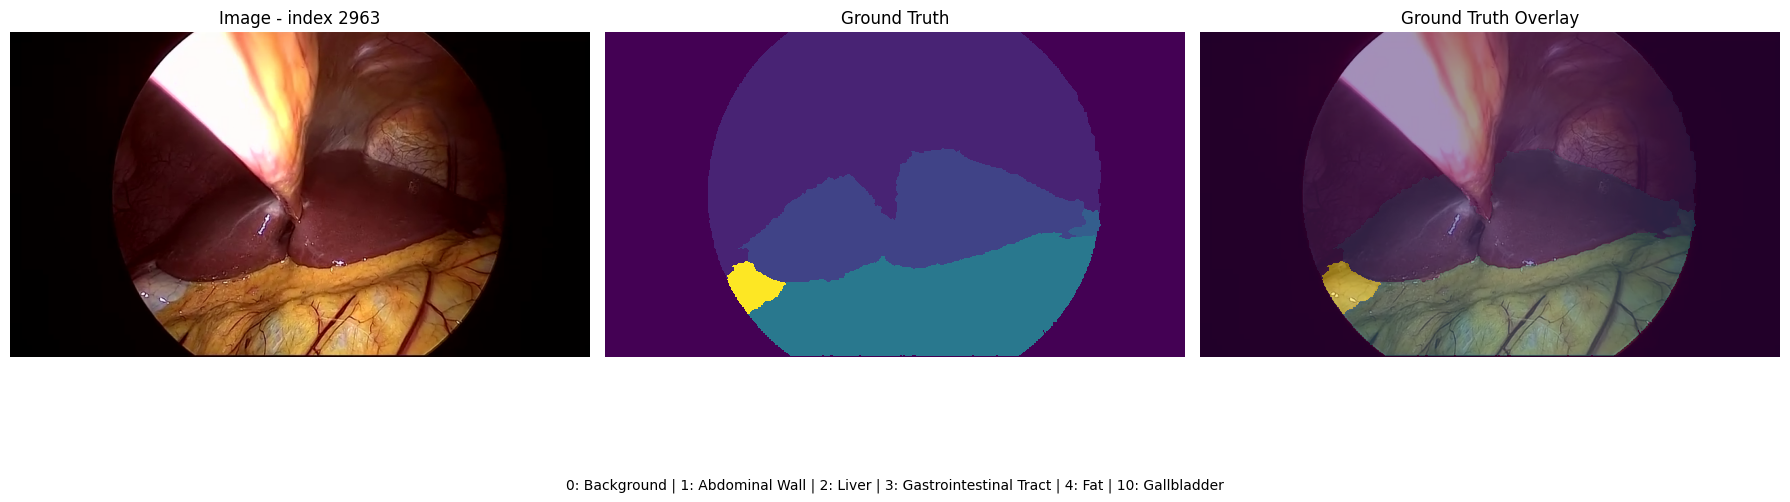

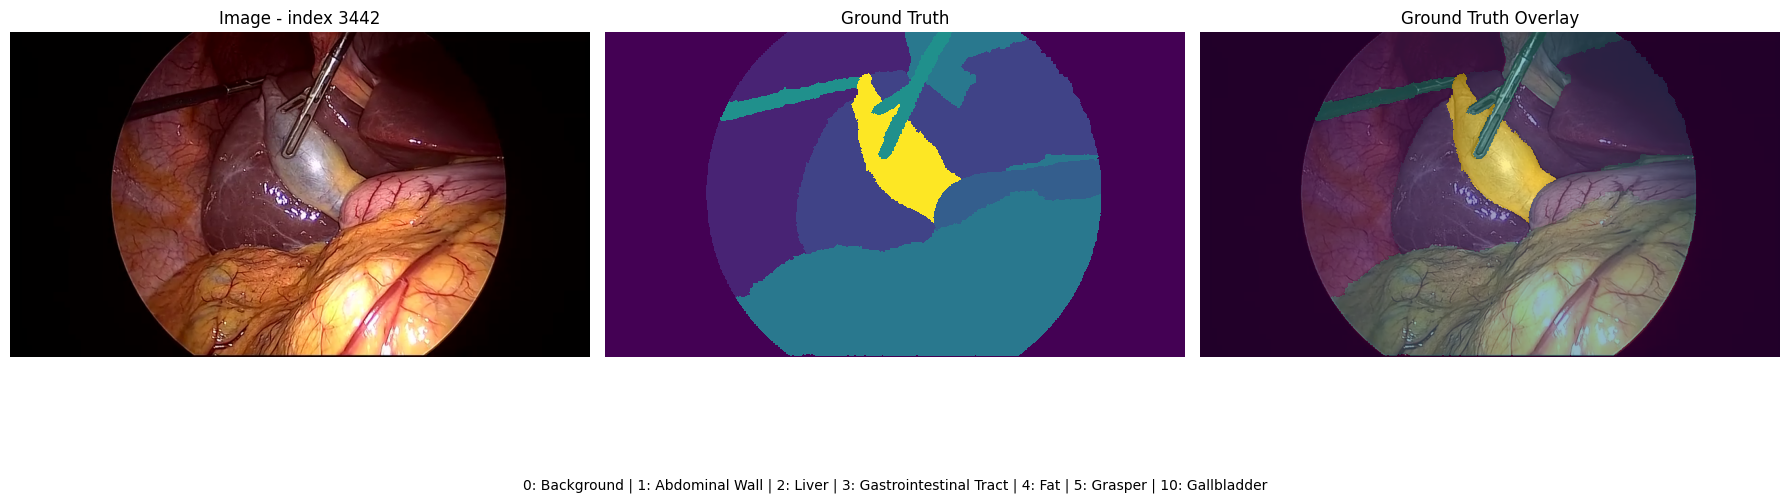

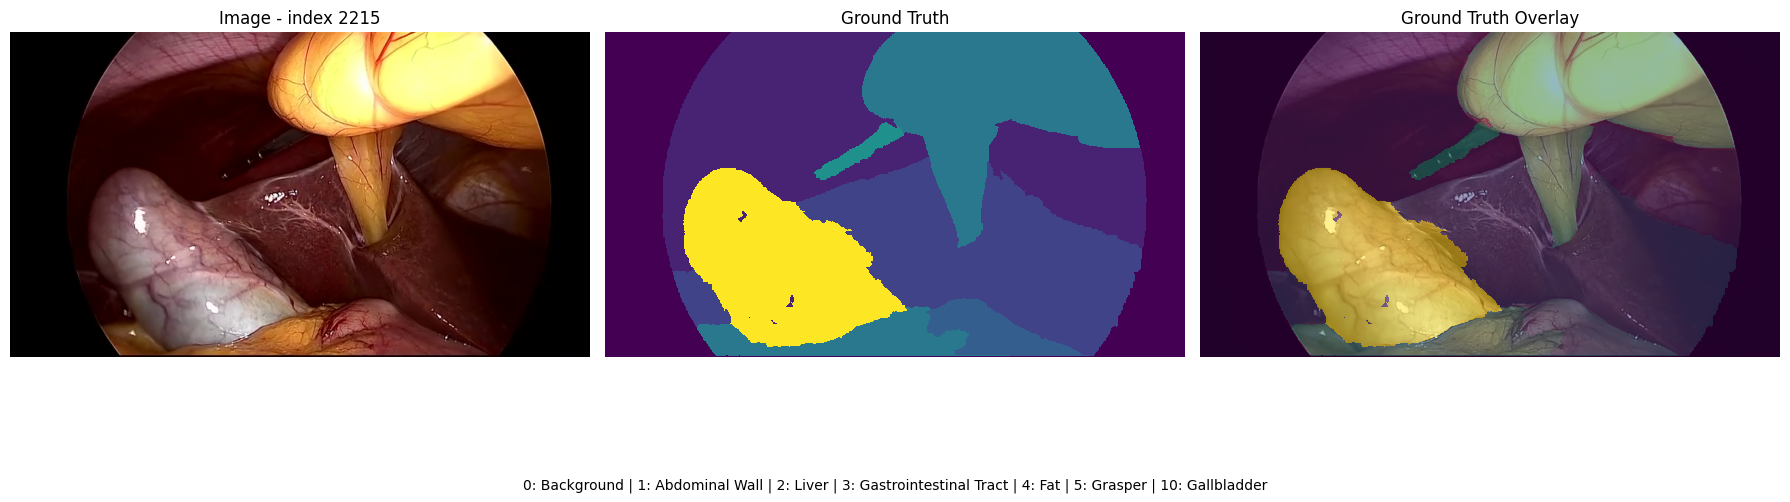

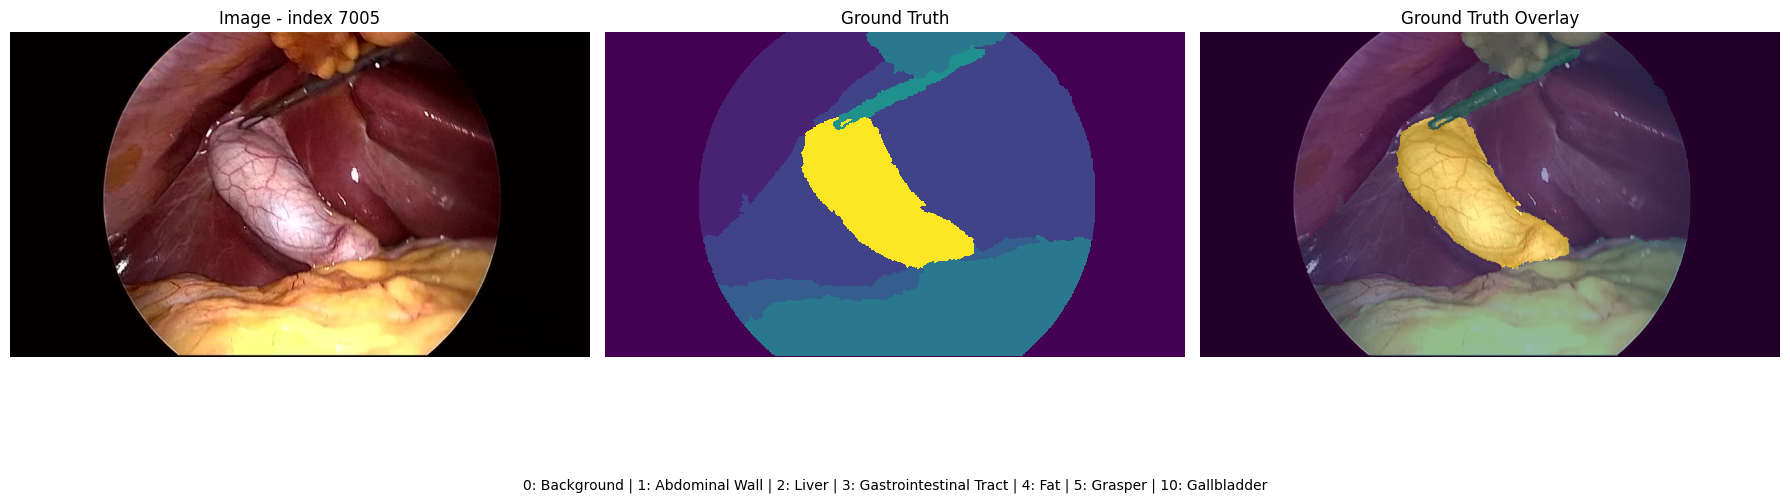

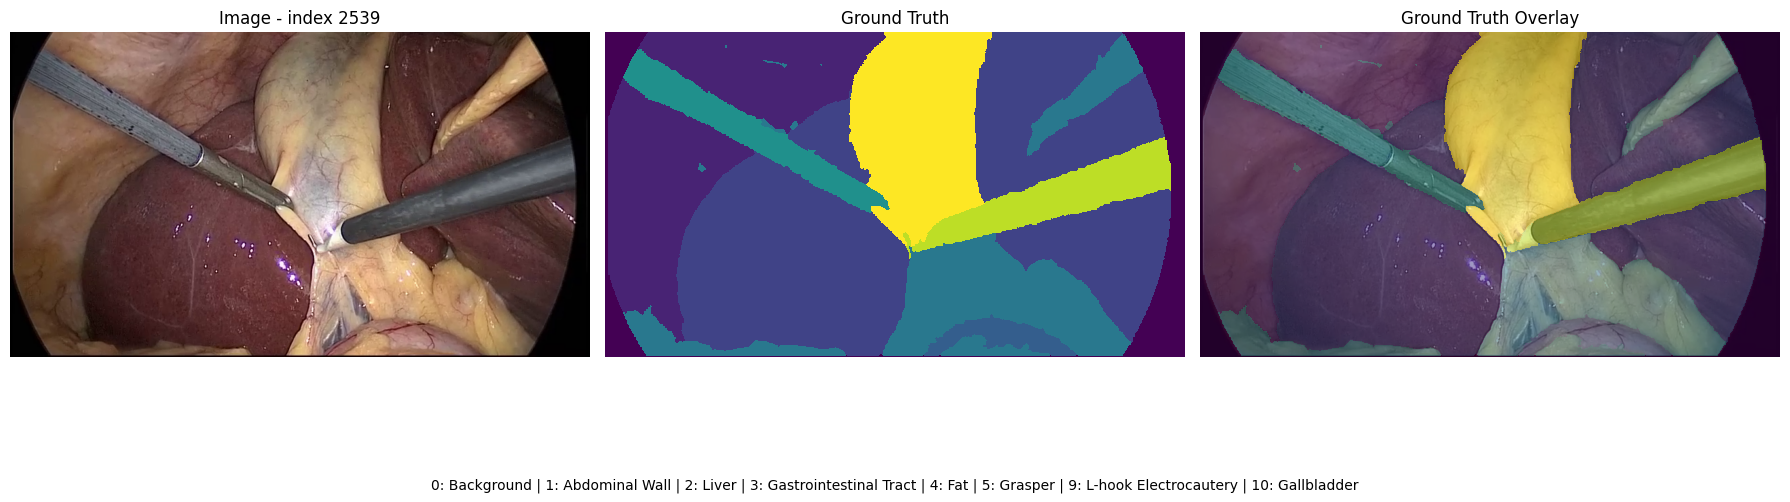

In [16]:
class_names = get_class_names(dataset)

visualize_random_samples(
    dataset=dataset,
    indices=splits["validation"],
    class_names=class_names,
    n_samples=5,
)

In [ ]:
# ============================================================
# GENERATE DATASET VALIDATION REPORT
# ============================================================

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.backends.backend_pdf import PdfPages


# ============================================================
# CONFIGURATION
# ============================================================

REPORT_DIR = (
    PROJECT_ROOT
    / "docs"
    / "reports"
    / "dataset_validation"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

DATASET_NAME = DATASET_CONFIG.split("/")[-1]

PDF_PATH = (
    REPORT_DIR
    / f"{DATASET_NAME}_validation_report.pdf"
)

N_QUALITATIVE_SAMPLES = 5


# ============================================================
# GENERAL SETTINGS
# ============================================================

PAGE_WIDTH = 8.27
PAGE_HEIGHT = 11.69

FIGURE_SIZE = (
    PAGE_WIDTH,
    PAGE_HEIGHT,
)


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def prepare_image_for_plot(image):
    """
    Convert an image to a matplotlib-compatible format.
    """

    image = np.asarray(image)

    if image.ndim == 2:
        return image

    if image.ndim == 3:

        # CHW -> HWC
        if image.shape[0] in (1, 3, 4):
            image = np.moveaxis(
                image,
                0,
                -1,
            )

        # HWC with one channel -> HW
        if image.shape[-1] == 1:
            image = image[..., 0]

    return image


def normalize_image_for_plot(image):
    """
    Normalize image values to [0, 1].
    """

    image = image.astype(np.float32)

    min_value = image.min()
    max_value = image.max()

    if max_value > min_value:
        image = (
            image - min_value
        ) / (
            max_value - min_value
        )

    return image


def get_image_and_mask(dataset, index):
    """
    Load a raw sample and extract image and mask.

    The function supports dictionary-based samples and
    tuple/list-based samples.
    """

    sample = load_raw_sample(
        dataset,
        int(index),
    )

    # Dictionary-based dataset sample
    if isinstance(sample, dict):

        image = sample.get(
            "image",
            sample.get("img"),
        )

        mask = sample.get(
            "mask",
            sample.get("label"),
        )

        if image is None or mask is None:
            raise ValueError(
                "Unable to identify image and mask. "
                f"Available keys: {list(sample.keys())}"
            )

        return (
            to_numpy(image),
            to_numpy(mask),
        )

    # Tuple/list-based dataset sample
    if isinstance(sample, (tuple, list)):

        if len(sample) < 2:
            raise ValueError(
                "Expected at least image and mask."
            )

        return (
            to_numpy(sample[0]),
            to_numpy(sample[1]),
        )

    raise ValueError(
        "Unsupported sample type: "
        f"{type(sample).__name__}"
    )


def add_header(
    fig,
    title,
    subtitle=None,
):
    """
    Add a consistent report header.
    """

    fig.text(
        0.07,
        0.95,
        title,
        fontsize=20,
        fontweight="bold",
        va="top",
    )

    if subtitle:
        fig.text(
            0.07,
            0.915,
            subtitle,
            fontsize=10,
            va="top",
        )


def add_footer(
    fig,
    page_text=None,
):
    """
    Add a consistent footer.
    """

    fig.text(
        0.07,
        0.025,
        "Dataset Validation Report",
        fontsize=8,
    )

    if page_text:
        fig.text(
            0.93,
            0.025,
            page_text,
            fontsize=8,
            ha="right",
        )


def add_table(
    ax,
    dataframe,
    columns,
    headers,
    font_size=8,
    scale=(1, 1.5),
):
    """
    Create a consistently formatted table.
    """

    table_data = dataframe[columns].values.tolist()

    table = ax.table(
        cellText=table_data,
        colLabels=headers,
        loc="center",
        cellLoc="center",
    )

    table.auto_set_font_size(False)
    table.set_fontsize(font_size)
    table.scale(
        scale[0],
        scale[1],
    )

    for cell in table.get_celld().values():
        cell.set_linewidth(0.5)

    return table


# ============================================================
# PREPARE DATA
# ============================================================

statistics_df = statistics.copy()

statistics_df["class"] = statistics_df[
    "class"
].astype(str)

split_names = list(
    statistics_df["split"].unique()
)

class_names = get_class_names(dataset)


# ============================================================
# REPORT
# ============================================================

with PdfPages(PDF_PATH) as pdf:

    total_pages = 0

    # ========================================================
    # 1. COVER PAGE
    # ========================================================

    fig = plt.figure(
        figsize=FIGURE_SIZE,
    )

    fig.patch.set_facecolor("white")

    fig.text(
        0.08,
        0.72,
        "Dataset Validation",
        fontsize=30,
        fontweight="bold",
    )

    fig.text(
        0.08,
        0.65,
        "Surgical Scene Semantic Segmentation",
        fontsize=17,
    )

    fig.text(
        0.08,
        0.56,
        f"Dataset: {DATASET_NAME}",
        fontsize=15,
        fontweight="bold",
    )

    fig.text(
        0.08,
        0.50,
        f"Number of classes: {len(class_names)}",
        fontsize=11,
    )

    fig.text(
        0.08,
        0.46,
        "Complete-dataset distribution analysis",
        fontsize=11,
    )

    fig.text(
        0.08,
        0.18,
        "This report evaluates class presence, pixel-level "
        "distribution, split consistency, and qualitative "
        "segmentation annotations.",
        fontsize=10,
        wrap=True,
        va="top",
    )

    fig.text(
        0.08,
        0.08,
        "All quantitative statistics are computed using "
        "the complete samples available in each split.",
        fontsize=9,
    )

    pdf.savefig(
        fig,
        bbox_inches="tight",
    )

    plt.close(fig)

    total_pages += 1

    # ========================================================
    # 2. DATASET OVERVIEW
    # ========================================================

    fig = plt.figure(
        figsize=FIGURE_SIZE,
    )

    add_header(
        fig,
        "1. Dataset Overview",
        f"Dataset: {DATASET_NAME}",
    )

    ax = fig.add_axes(
        [0.08, 0.55, 0.84, 0.25]
    )

    overview_df = pd.DataFrame(
        [
            {
                "Split": split_name,
                "Samples": len(
                    splits[split_name]
                ),
            }
            for split_name in split_names
        ]
    )

    add_table(
        ax,
        overview_df,
        ["Split", "Samples"],
        ["Split", "Number of samples"],
        font_size=10,
        scale=(1, 2),
    )

    ax.axis("off")

    # Class list
    fig.text(
        0.08,
        0.46,
        "Classes",
        fontsize=14,
        fontweight="bold",
    )

    class_text = "\n".join(
        f"{idx:>2}  —  {name}"
        for idx, name in enumerate(
            class_names
        )
    )

    fig.text(
        0.10,
        0.42,
        class_text,
        fontsize=9,
        va="top",
        family="monospace",
    )

    # Methodology
    fig.text(
        0.08,
        0.12,
        "Methodology",
        fontsize=14,
        fontweight="bold",
    )

    fig.text(
        0.08,
        0.08,
        "The validation procedure evaluates every sample in each "
        "split. No sampling or maximum-sample limit is applied "
        "to the quantitative analysis.",
        fontsize=9,
        wrap=True,
    )

    add_footer(
        fig,
        f"Page {total_pages + 1}",
    )

    pdf.savefig(
        fig,
        bbox_inches="tight",
    )

    plt.close(fig)

    total_pages += 1

    # ========================================================
    # 3. CLASS PRESENCE
    # ========================================================

    for split_name in split_names:

        split_df = statistics_df[
            statistics_df["split"]
            == split_name
        ].copy()

        split_df = split_df.sort_values(
            "class_id"
        )

        fig = plt.figure(
            figsize=FIGURE_SIZE,
        )

        add_header(
            fig,
            "2. Class Presence",
            f"Split: {split_name}",
        )

        ax = fig.add_axes(
            [0.08, 0.55, 0.84, 0.30]
        )

        table_df = split_df.copy()

        table_df["samples"] = table_df[
            "samples"
        ].map(
            lambda x: f"{int(x):,}"
        )

        table_df["sample_percentage"] = (
            table_df["sample_percentage"]
            .map(
                lambda x: f"{x:.2f}%"
            )
        )

        add_table(
            ax,
            table_df,
            [
                "class",
                "samples",
                "sample_percentage",
            ],
            [
                "Class",
                "Samples",
                "Samples containing class",
            ],
            font_size=8,
            scale=(1, 1.6),
        )

        ax.axis("off")

        # Chart
        chart_ax = fig.add_axes(
            [0.13, 0.12, 0.75, 0.30]
        )

        ordered_df = split_df.sort_values(
            "sample_percentage"
        )

        chart_ax.barh(
            ordered_df["class"],
            ordered_df["sample_percentage"],
        )

        chart_ax.set_xlabel(
            "Samples containing class (%)"
        )

        chart_ax.set_title(
            "Class occurrence within the split"
        )

        chart_ax.set_xlim(
            0,
            100,
        )

        chart_ax.grid(
            axis="x",
            alpha=0.3,
        )

        add_footer(
            fig,
            f"Page {total_pages + 1}",
        )

        pdf.savefig(
            fig,
            bbox_inches="tight",
        )

        plt.close(fig)

        total_pages += 1

    # ========================================================
    # 4. PIXEL DISTRIBUTION
    # ========================================================

    for split_name in split_names:

        split_df = statistics_df[
            statistics_df["split"]
            == split_name
        ].copy()

        split_df = split_df.sort_values(
            "class_id"
        )

        fig = plt.figure(
            figsize=FIGURE_SIZE,
        )

        add_header(
            fig,
            "3. Pixel Distribution",
            f"Split: {split_name}",
        )

        ax = fig.add_axes(
            [0.08, 0.55, 0.84, 0.30]
        )

        table_df = split_df.copy()

        table_df["pixels"] = table_df[
            "pixels"
        ].map(
            lambda x: f"{int(x):,}"
        )

        table_df["pixel_percentage"] = (
            table_df["pixel_percentage"]
            .map(
                lambda x: f"{x:.4f}%"
            )
        )

        add_table(
            ax,
            table_df,
            [
                "class",
                "pixels",
                "pixel_percentage",
            ],
            [
                "Class",
                "Pixels",
                "Pixel distribution",
            ],
            font_size=8,
            scale=(1, 1.6),
        )

        ax.axis("off")

        # Chart
        chart_ax = fig.add_axes(
            [0.13, 0.12, 0.75, 0.30]
        )

        ordered_df = split_df.sort_values(
            "pixel_percentage"
        )

        chart_ax.barh(
            ordered_df["class"],
            ordered_df["pixel_percentage"],
        )

        chart_ax.set_xlabel(
            "Pixels (%)"
        )

        chart_ax.set_title(
            "Pixel-level class distribution"
        )

        chart_ax.grid(
            axis="x",
            alpha=0.3,
        )

        add_footer(
            fig,
            f"Page {total_pages + 1}",
        )

        pdf.savefig(
            fig,
            bbox_inches="tight",
        )

        plt.close(fig)

        total_pages += 1

    # ========================================================
    # 5. CROSS-SPLIT COMPARISON
    # ========================================================

    presence_pivot = statistics_df.pivot(
        index="class",
        columns="split",
        values="sample_percentage",
    ).fillna(0)

    fig, ax = plt.subplots(
        figsize=(12, 6),
    )

    presence_pivot.plot(
        kind="bar",
        ax=ax,
    )

    ax.set_title(
        "Class Presence Across Splits",
        fontsize=16,
        fontweight="bold",
    )

    ax.set_xlabel(
        "Class"
    )

    ax.set_ylabel(
        "Samples containing class (%)"
    )

    ax.set_ylim(
        0,
        100,
    )

    ax.grid(
        axis="y",
        alpha=0.3,
    )

    ax.legend(
        title="Split"
    )

    plt.xticks(
        rotation=45,
        ha="right",
    )

    plt.tight_layout()

    pdf.savefig(fig)

    plt.close(fig)

    total_pages += 1

    # --------------------------------------------------------
    # Pixel comparison
    # --------------------------------------------------------

    pixel_pivot = statistics_df.pivot(
        index="class",
        columns="split",
        values="pixel_percentage",
    ).fillna(0)

    fig, ax = plt.subplots(
        figsize=(12, 6),
    )

    pixel_pivot.plot(
        kind="bar",
        ax=ax,
    )

    ax.set_title(
        "Pixel Distribution Across Splits",
        fontsize=16,
        fontweight="bold",
    )

    ax.set_xlabel(
        "Class"
    )

    ax.set_ylabel(
        "Pixels (%)"
    )

    ax.grid(
        axis="y",
        alpha=0.3,
    )

    ax.legend(
        title="Split"
    )

    plt.xticks(
        rotation=45,
        ha="right",
    )

    plt.tight_layout()

    pdf.savefig(fig)

    plt.close(fig)

    total_pages += 1

    # ========================================================
    # 6. QUALITATIVE ANALYSIS
    # ========================================================

    for split_name, indices in splits.items():

        if not indices:
            continue

        rng = np.random.default_rng(
            seed=42
        )

        n_samples = min(
            N_QUALITATIVE_SAMPLES,
            len(indices),
        )

        selected_indices = rng.choice(
            indices,
            size=n_samples,
            replace=False,
        )

        for index in selected_indices:

            image, mask = (
                get_image_and_mask(
                    dataset,
                    int(index),
                )
            )

            image = (
                prepare_image_for_plot(
                    image
                )
            )

            image = (
                normalize_image_for_plot(
                    image
                )
            )

            mask = np.squeeze(mask)

            fig, axes = plt.subplots(
                1,
                3,
                figsize=(15, 5),
            )

            fig.suptitle(
                (
                    "4. Qualitative Analysis — "
                    f"{split_name} — Sample {index}"
                ),
                fontsize=16,
                fontweight="bold",
            )

            # ------------------------------------------------
            # Image
            # ------------------------------------------------

            axes[0].imshow(
                image
            )

            axes[0].set_title(
                "Reference Image",
                fontsize=13,
            )

            axes[0].axis("off")

            # ------------------------------------------------
            # Ground truth
            # ------------------------------------------------

            axes[1].imshow(
                mask,
                interpolation="nearest",
                vmin=0,
                vmax=len(class_names) - 1,
            )

            axes[1].set_title(
                "Ground Truth",
                fontsize=13,
            )

            axes[1].axis("off")

            # ------------------------------------------------
            # Overlay
            # ------------------------------------------------

            axes[2].imshow(
                image
            )

            axes[2].imshow(
                mask,
                alpha=0.5,
                interpolation="nearest",
                vmin=0,
                vmax=len(class_names) - 1,
            )

            axes[2].set_title(
                "Ground Truth Overlay",
                fontsize=13,
            )

            axes[2].axis("off")

            # ------------------------------------------------
            # Present classes
            # ------------------------------------------------

            present_classes = np.unique(
                mask
            )

            present_names = []

            for class_id in present_classes:

                class_id = int(
                    class_id
                )

                if (
                    0
                    <= class_id
                    < len(class_names)
                ):
                    present_names.append(
                        class_names[class_id]
                    )

            if present_names:

                fig.text(
                    0.5,
                    0.025,
                    "Present classes: "
                    + ", ".join(
                        present_names
                    ),
                    ha="center",
                    fontsize=9,
                )

            plt.tight_layout(
                rect=(
                    0,
                    0.05,
                    1,
                    0.92,
                )
            )

            pdf.savefig(fig)

            plt.close(fig)

            total_pages += 1

    # ========================================================
    # 7. AUTOMATIC SUMMARY
    # ========================================================

    fig = plt.figure(
        figsize=FIGURE_SIZE,
    )

    add_header(
        fig,
        "5. Validation Summary",
        f"Dataset: {DATASET_NAME}",
    )

    summary_lines = []

    summary_lines.append(
        f"Number of classes: {len(class_names)}"
    )

    summary_lines.append("")

    # --------------------------------------------------------
    # Split sizes
    # --------------------------------------------------------

    summary_lines.append(
        "Split sizes:"
    )

    for split_name in split_names:

        summary_lines.append(
            f"  • {split_name}: "
            f"{len(splits[split_name]):,} samples"
        )

    summary_lines.append("")

    # --------------------------------------------------------
    # Rare classes
    # --------------------------------------------------------

    summary_lines.append(
        "Class presence:"
    )

    for split_name in split_names:

        split_df = statistics_df[
            statistics_df["split"]
            == split_name
        ]

        rarest = split_df.loc[
            split_df[
                "sample_percentage"
            ].idxmin()
        ]

        summary_lines.append(
            f"  • {split_name}: "
            f"{rarest['class']} has the lowest "
            f"sample presence "
            f"({rarest['sample_percentage']:.2f}%)."
        )

    summary_lines.append("")

    # --------------------------------------------------------
    # Pixel imbalance
    # --------------------------------------------------------

    summary_lines.append(
        "Pixel distribution:"
    )

    for split_name in split_names:

        split_df = statistics_df[
            statistics_df["split"]
            == split_name
        ]

        rarest = split_df.loc[
            split_df[
                "pixel_percentage"
            ].idxmin()
        ]

        dominant = split_df.loc[
            split_df[
                "pixel_percentage"
            ].idxmax()
        ]

        summary_lines.append(
            f"  • {split_name}: "
            f"{dominant['class']} is the dominant "
            f"class ({dominant['pixel_percentage']:.2f}%), "
            f"while {rarest['class']} has the smallest "
            f"pixel share "
            f"({rarest['pixel_percentage']:.4f}%)."
        )

    summary_lines.append("")

    # --------------------------------------------------------
    # Methodological interpretation
    # --------------------------------------------------------

    summary_lines.append(
        "Interpretation:"
    )

    summary_lines.append(
        "  • Sample presence measures how frequently "
        "a class occurs across images."
    )

    summary_lines.append(
        "  • Pixel distribution measures how much "
        "image area is occupied by each class."
    )

    summary_lines.append(
        "  • These two statistics describe different "
        "forms of class imbalance."
    )

    summary_lines.append(
        "  • Differences between splits should be "
        "considered when interpreting model performance."
    )

    summary_lines.append(
        "  • Group-level stratification cannot guarantee "
        "that every rare class appears in every split."
    )

    ax = fig.add_axes(
        [0.08, 0.12, 0.84, 0.75]
    )

    ax.axis("off")

    ax.text(
        0,
        1,
        "\n".join(summary_lines),
        fontsize=10,
        va="top",
        linespacing=1.8,
    )

    add_footer(
        fig,
        f"Page {total_pages + 1}",
    )

    pdf.savefig(
        fig,
        bbox_inches="tight",
    )

    plt.close(fig)

    total_pages += 1


# ============================================================
# FINAL MESSAGE
# ============================================================

print()
print("=" * 70)
print("DATASET VALIDATION REPORT")
print("=" * 70)
print()
print(f"Dataset : {DATASET_NAME}")
print(f"Pages   : {total_pages}")
print(f"Output  : {PDF_PATH.resolve()}")
print()
print("Report successfully generated.")